# 05 · Fourier analysis: where do training and test images still differ?

After `hist_split`, brightness and colour of training and test images match (`04_haze_correction`), but
the contrast inside the images does not. Here the images are looked at in the **frequency domain**:
the 2-D Fourier transform splits every image into patterns from coarse (low frequencies: large
structures, overall light/dark areas) to fine (high frequencies: edges, small details).

Three Fourier methods are compared **without training**:

| | Method | Where | Idea |
|---|---|---|---|
| **A** | Fourier Domain Adaptation (FDA) | training augmentation | mix a training image's low-frequency amplitudes with those of a random Kaggle image (land with land, water with water) |
| **B** | Spectral matching | preprocessing of training images | per band and frequency, scale amplitudes so the average profile matches the Kaggle images (histogram matching per frequency) |
| **C** | Low-frequency equaliser | fixed first layer of the model, **training and test** | bring every image's low-frequency energy to the same level per band, so haze-related large-scale contrast differences disappear by design |

All methods keep the **phase** of the Fourier transform, which holds the shapes and edges that define
the class; only amplitudes (how strong each pattern is) are changed. Code: `src/fourier.py`.
Each method is trained in its own notebook afterwards (`E05`–`E07`).

## 1 · Setup and data

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS, band_index, load_split, load_test, load_train
from src.fourier import (RADIUS_EDGES, FourierDomainAugment, SpectralMatcher, equalize_low_freq_np,
                         low_freq_energy, radial_amplitude, radius_grid)
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style
from src.preprocessing import land_mask, load_matcher
from src.utils import get_device, seed_everything

apply_style()
seed_everything(0)
device = get_device()

X_all, meta = load_train()
X_kg = np.asarray(load_test()[0])
split = load_split()
hist_split = load_matcher(PROJECT_ROOT / "artifacts" / "preprocessing" / "hist_split.json")

# Everything starts from the current best preprocessing: hist_split-corrected EuroSAT images
X_tr = hist_split(np.asarray(X_all[np.flatnonzero(split["split"] == "train")]))
X_va = hist_split(np.asarray(X_all[np.flatnonzero(split["split"] == "val")]))
y_va = split.loc[split["split"] == "val", "label"].values
land_tr, land_va, land_kg = land_mask(X_tr), land_mask(X_va), land_mask(X_kg)
print(f"train {len(X_tr):,}  val {len(X_va):,}  Kaggle {len(X_kg):,}")

train 18,900  val 4,050  Kaggle 4,232


## 2 · The spectrum before any Fourier correction

Ratio of the average amplitude (Kaggle ÷ `hist_split`-corrected validation images) per band and
frequency, for **land** images (water is compared separately in the methods). 1.0 = identical,
above 1 = the test images have stronger patterns at that scale.

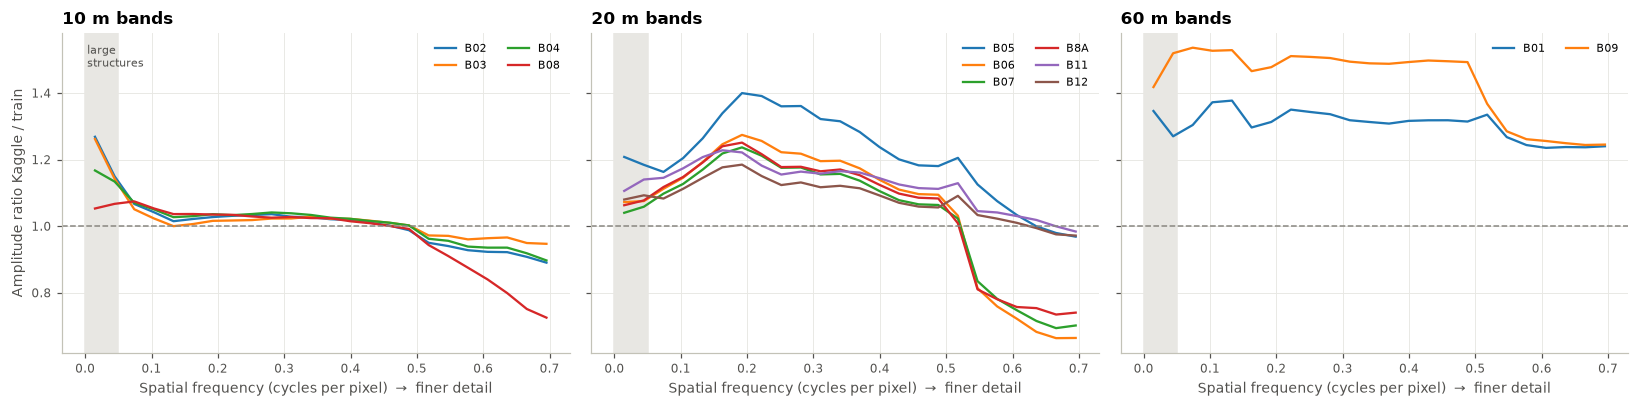

In [2]:
centres = (RADIUS_EDGES[:-1] + RADIUS_EDGES[1:]) / 2
ratio_before = radial_amplitude(X_kg[land_kg]) / radial_amplitude(X_va[land_va])

groups = {"10 m bands": ["B02", "B03", "B04", "B08"],
          "20 m bands": ["B05", "B06", "B07", "B8A", "B11", "B12"],
          "60 m bands": ["B01", "B09"]}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (title, bands) in zip(axes, groups.items()):
    for b in bands:
        ax.plot(centres, ratio_before[band_index(b)], lw=1.5, label=b)
    ax.axhline(1, color=MUTED, ls="--", lw=1)
    ax.axvspan(0, 0.05, color="#e8e7e3", zorder=0)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Spatial frequency (cycles per pixel)  →  finer detail")
    ax.legend(ncol=2, fontsize=7)
axes[0].set_ylabel("Amplitude ratio Kaggle / train")
axes[0].text(0.003, axes[0].get_ylim()[1] * 0.98, "large\nstructures", fontsize=7, va="top", color="#52514e")
plt.tight_layout()
plt.show()

- **10 m bands:** the test images are stronger **only at the lowest frequencies** (grey area): haze flattens large-scale light/dark differences, fine details are the same.
- **20 m bands:** stronger at **medium frequencies**: these bands were enlarged from 20 m to 10 m pixels with a different method (see `01_eda`, section 4).
- **60 m bands (B01, B09):** stronger everywhere: these atmospheric bands differ the most overall.

## 3 · Apply the three methods

- **A** is random: every training image gets a random Kaggle partner and a random blend weight. Here it is applied once with blend weight 1 (the strongest version) to show its full effect.
- **B** is fitted on the training split and the Kaggle images, then applied to the validation images.
- **C** is applied to **both** sides. Its target level per band is the median low-frequency energy of the training images; each image is scaled by at most 1.5× up or down.

In [3]:
# B · spectral matching
spectral = SpectralMatcher.fit(X_tr, X_kg)
va_B = spectral(X_va)

# C · low-frequency equaliser (target: median of the training images), applied to both sides
template = np.median(low_freq_energy(X_tr[::4]), axis=0)
# max_factor 1.5: amplify/damp by at most 1.5x. With 3x, every uniform Forest image was boosted >1.5x,
# creating blotchy patterns; 1.5 gives the same contrast effect (classifier 74.8% vs 75.1%).
va_C = equalize_low_freq_np(X_va, template, max_factor=1.5)
kg_C = equalize_low_freq_np(X_kg, template, max_factor=1.5)

# A · FDA with full blending, on the GPU
torch.manual_seed(0)
kg_dev = torch.from_numpy(np.minimum(X_kg, 32767).astype(np.int16)).to(device)
fda = FourierDomainAugment(kg_dev, nir_index=band_index("B08"), p=1.0, max_blend=1.0)
fda.max_blend = 1.0
va_A = np.concatenate([
    fda(torch.from_numpy(X_va[i:i + 512].astype(np.float32)).to(device)).cpu().numpy()
    for i in range(0, len(X_va), 512)])

# Each version as (training-side images, Kaggle-side images)
versions = {
    "hist_split (current)": (X_va, X_kg),
    "A · FDA": (va_A, X_kg),
    "B · spectral matching": (va_B, X_kg),
    "C · low-freq equaliser": (va_C, kg_C),
}
COLORS = {"hist_split (current)": TRAIN_COLOR, "A · FDA": "#1baf7a", "B · spectral matching": "#eda100",
          "C · low-freq equaliser": "#4a3aa7"}

## 4 · Measure 1: spectrum ratio after each method

Same plot as section 2, one band per resolution group, for land images. The closer to 1.0 across
all frequencies, the better.

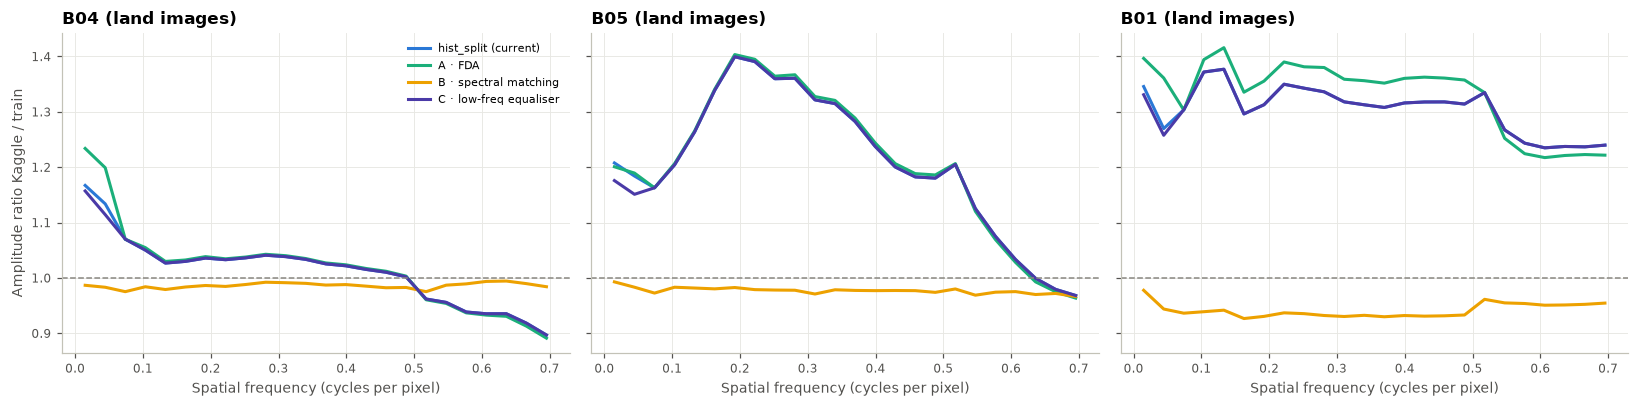

,spectral gap (land)
hist_split (current),0.146
A · FDA,0.151
B · spectral matching,0.020
C · low-freq equaliser,0.144


In [4]:
show = ["B04", "B05", "B01"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
ratios = {}
for name, (tr_side, kg_side) in versions.items():
    ratios[name] = radial_amplitude(kg_side[land_mask(X_kg)]) / radial_amplitude(tr_side[land_va])
    for ax, b in zip(axes, show):
        ax.plot(centres, ratios[name][band_index(b)], color=COLORS[name], label=name)
for ax, b in zip(axes, show):
    ax.axhline(1, color=MUTED, ls="--", lw=1)
    ax.set_title(f"{b} (land images)", loc="left")
    ax.set_xlabel("Spatial frequency (cycles per pixel)")
axes[0].set_ylabel("Amplitude ratio Kaggle / train")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

def spectral_gap(r):
    """Mean |log ratio| over bands and frequencies: 0 = identical spectra."""
    return float(np.abs(np.log(r)).mean())

gap = pd.Series({name: spectral_gap(r) for name, r in ratios.items()}, name="spectral gap (land)")
gap.round(3).to_frame()

## 5 · Measure 2: can a classifier still tell training from test images?

Like `04_haze_correction`: a logistic regression tries to tell (corrected) validation images from Kaggle
images, using one group of image features at a time. 50% = indistinguishable. Land images only.
The new feature group **spectrum** is each image's amplitude in 6 frequency rings per band, relative
to its overall contrast.

In [5]:
def image_spectrum(x, edges=(0, 0.03, 0.06, 0.1, 0.2, 0.35, 0.71)):
    x = np.asarray(x, dtype=np.float32)
    x = x - x.mean(axis=(2, 3), keepdims=True)
    amp = np.abs(np.fft.fft2(x))
    ring = np.digitize(radius_grid(x.shape[-1]), edges[1:-1])
    prof = np.stack([amp[..., ring == k].mean(axis=-1) for k in range(len(edges) - 1)], axis=-1)
    prof = prof / (prof.mean(axis=-1, keepdims=True) + 1e-6)
    return np.log(prof + 1e-6).reshape(len(x), -1)

feature_groups = {
    "brightness": lambda x: np.asarray(x, np.float32).mean(axis=(2, 3)),
    "contrast": lambda x: np.asarray(x, np.float32).std(axis=(2, 3)),
    "spectrum": image_spectrum,
}

def separability(fa, fb, seed=0):
    n = min(len(fa), len(fb))
    r = np.random.default_rng(seed)
    fa, fb = fa[r.choice(len(fa), n, replace=False)], fb[r.choice(len(fb), n, replace=False)]
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return cross_val_score(clf, np.vstack([fa, fb]), np.r_[np.zeros(n), np.ones(n)], cv=5).mean()

sep = pd.DataFrame({
    name: {g: separability(f(tr_side[land_va]), f(kg_side[land_kg])) * 100 for g, f in feature_groups.items()}
    for name, (tr_side, kg_side) in versions.items()
}).T.round(1)
sep["all three"] = [separability(np.hstack([f(t[land_va]) for f in feature_groups.values()]),
                                 np.hstack([f(k[land_kg]) for f in feature_groups.values()])) * 100
                    for t, k in versions.values()]
sep = sep.round(1)
sep

,brightness,contrast,spectrum,all three
hist_split (current),53.7,84.3,97.9,98.7
A · FDA,53.8,69.8,97.7,98.7
B · spectral matching,54.0,59.2,81.0,82.9
C · low-freq equaliser,53.7,74.8,97.5,98.5


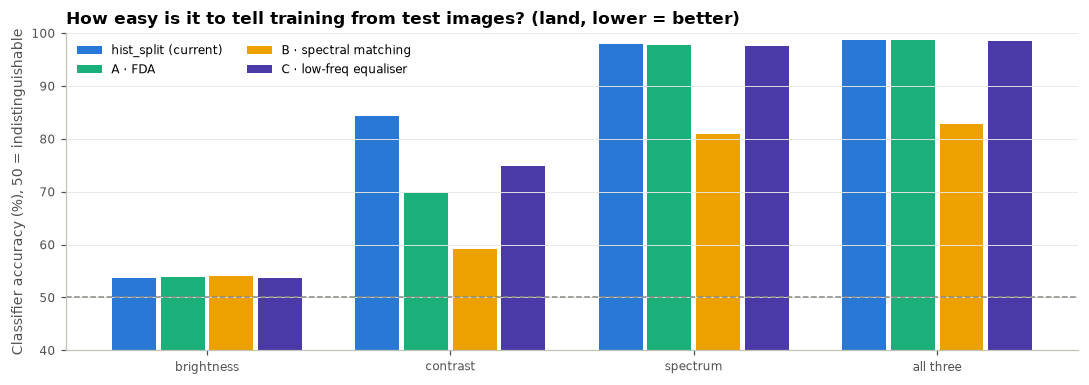

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(sep.columns))
w = 0.2
for i, name in enumerate(sep.index):
    ax.bar(x + (i - 1.5) * w, sep.loc[name], w - 0.02, color=COLORS[name], label=name)
ax.axhline(50, color=MUTED, ls="--", lw=1)
ax.set_xticks(x, sep.columns)
ax.set_ylim(40, 100)
ax.set_ylabel("Classifier accuracy (%), 50 = indistinguishable")
ax.set_title("How easy is it to tell training from test images? (land, lower = better)", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

## 6 · What the methods do to an image

One validation image per class, the same Kaggle-style display scaling for all rows. A's partner
images are random, so A looks different on every call.

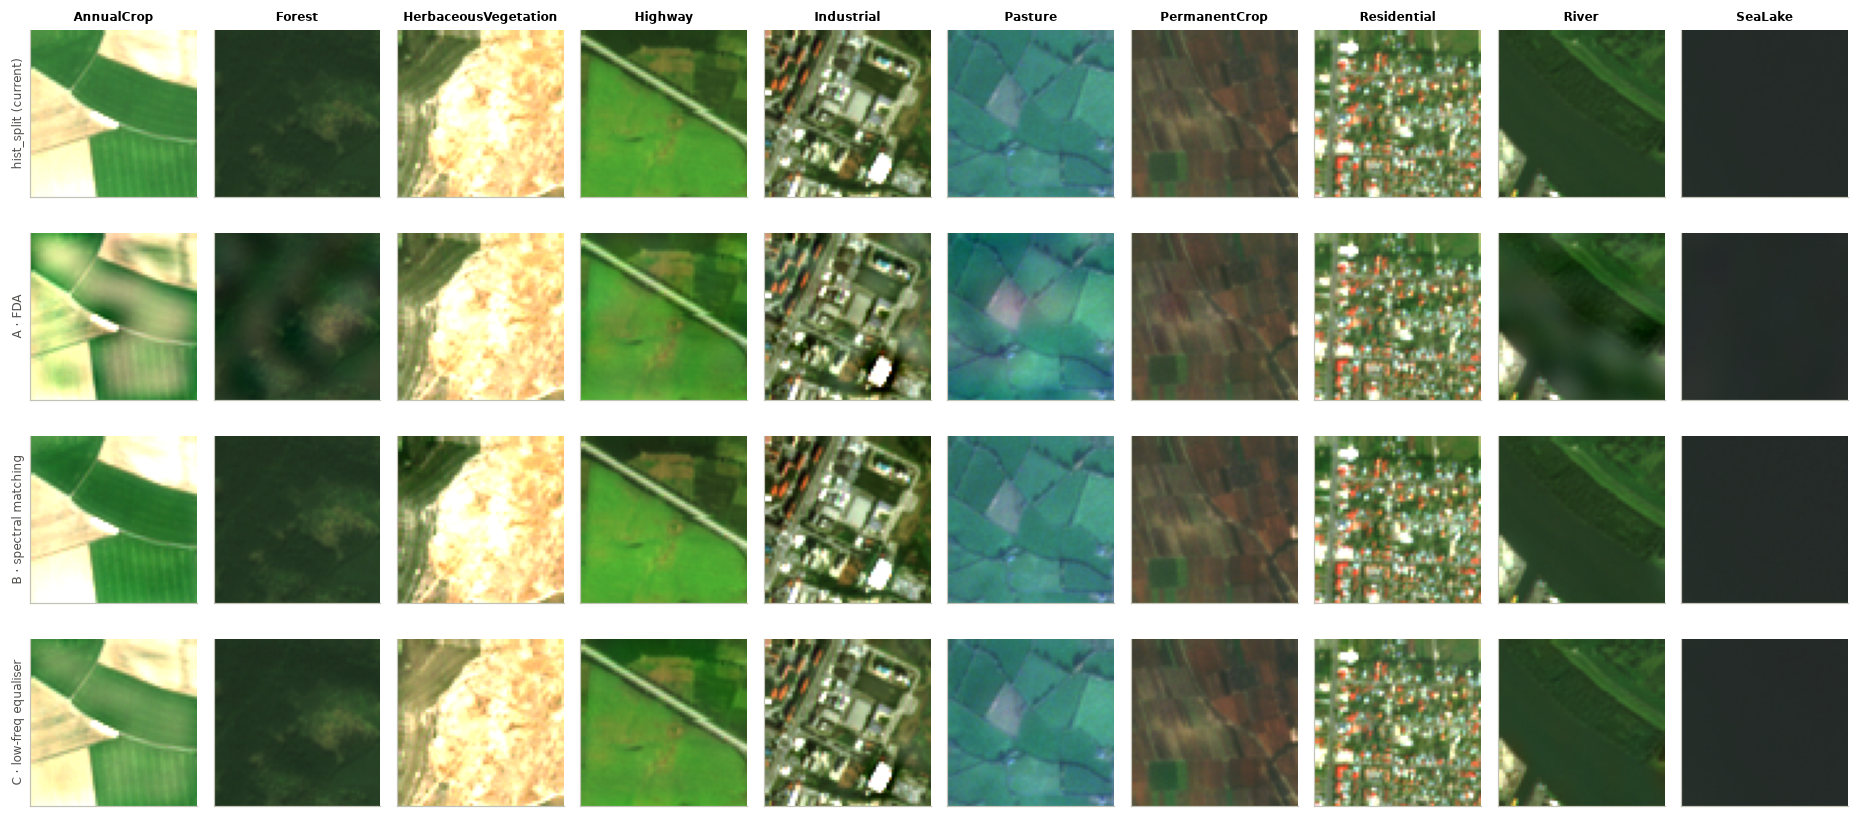

In [7]:
rgb = [band_index(b) for b in ["B04", "B03", "B02"]]
to_rgb = lambda img, vmax=1500: np.clip(np.asarray(img, np.float32)[rgb] / vmax, 0, 1).transpose(1, 2, 0)
examples = [np.flatnonzero(y_va == c)[3] for c in CLASSES]
rows = {"hist_split (current)": X_va, "A · FDA": va_A, "B · spectral matching": va_B, "C · low-freq equaliser": va_C}

fig, axes = plt.subplots(len(rows), len(CLASSES), figsize=(17, 7.8))
for r, (name, imgs) in enumerate(rows.items()):
    for c, i in enumerate(examples):
        axes[r, c].imshow(to_rgb(imgs[i]))
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
        if r == 0:
            axes[r, c].set_title(CLASSES[c], fontsize=8)
    axes[r, 0].set_ylabel(name, fontsize=8)
plt.tight_layout()
plt.show()

## 7 · Save

In [8]:
out_dir = PROJECT_ROOT / "artifacts" / "preprocessing"
spectral.save(out_dir / "spectral_match.json")
results = pd.concat([gap.round(3), sep.add_prefix("classifier % ")], axis=1)
results.to_csv(out_dir / "fourier_comparison.csv")
print("Saved", (out_dir / "spectral_match.json").relative_to(PROJECT_ROOT), "and",
      (out_dir / "fourier_comparison.csv").relative_to(PROJECT_ROOT))
results

Saved artifacts/preprocessing/spectral_match.json and artifacts/preprocessing/fourier_comparison.csv


,spectral gap (land),classifier % brightness,classifier % contrast,classifier % spectrum,classifier % all three
hist_split (current),0.146,53.7,84.3,97.9,98.7
A · FDA,0.151,53.8,69.8,97.7,98.7
B · spectral matching,0.020,54.0,59.2,81.0,82.9
C · low-freq equaliser,0.144,53.7,74.8,97.5,98.5


## 8 · Conclusion

| Method | Spectrum gap | Classifier: contrast | Classifier: spectrum | Side effects |
|---|---|---|---|---|
| hist_split (current) | 0.146 | 84% | 98% | – |
| A · FDA (full blend shown) | 0.151 | 70% | 98% | blotchy large-scale patterns at full strength; in training it is applied to half the images with a random blend weight |
| **B · spectral matching** | **0.020** | **59%** | **81%** | none visible |
| C · low-freq equaliser | 0.139 | 75% | 98% | slight blotches in uniform images (Forest, AnnualCrop) |

- **The detail profile is the strongest remaining giveaway:** with spectrum features, a simple classifier tells training from test images apart 98% of the time, more than with contrast (84%). Most of it comes from the **20 m bands**, which were upsampled differently in the two datasets, and from the **60 m bands**.
- **B fixes it best:** the spectra match within about 2% across all bands and frequencies, contrast becomes almost indistinguishable (59%), and the spectrum classifier drops to 81%.
- **A and C** only act on the lowest frequencies, so they reduce the contrast difference (to 70% / 75%) but leave the detail profile untouched.
- Expectation for training: **B > A ≈ C**. All three are trained in `E05_fourier_A_fda`, `E06_fourier_B_spectral` and `E07_fourier_C_layer`, each on top of the current best setup (`hist_split` + contrast augmentation + AdaBN).

**Actual Kaggle results** (all with AdaBN; best without Fourier: 68.18%): A · FDA 66.26%, B · spectral matching 67.85%,
C · Fourier layer 67.90%. None improved the score. B removed the spectrum difference almost completely, but it made
no difference to the model: a difference that is easy to *detect* is not necessarily one that *hurts*.
